SHAP Explainability for the VGG16 Chest X-ray Classifier

Loads the checkpoint saved by vgg16_chest_xray.py and uses
SHAP's GradientExplainer to visualize which pixels pushed the
model toward NORMAL vs PNEUMONIA for a handful of test images.

This is a standalone script. It does NOT import
vgg16_chest_xray.py, because that file runs the data split and
a full training run as soon as it's executed. Only the few
settings needed to rebuild the model and preprocess images the
same way are duplicated here.

Requires: pip install shap
Run this after models/vgg16_best.pth exists.

## 1. IMPORTS

In [7]:
from pathlib import Path
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import shap
import torch
from torch import nn
from torchvision import datasets, models, transforms

## 2. CONFIGURATION

In [8]:
PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_PATH = MODEL_DIR / "vgg16_best.pth"
EXPLANATIONS_DIR = PROJECT_ROOT / "explanations"

IMAGE_SIZE = 224
NUM_CLASSES = 2
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]

N_BACKGROUND = 50  # background images SHAP uses as its reference distribution
N_CORRECT = 2          # correctly predicted test images to visualize
N_MISCLASSIFIED = 2    # misclassified test images to visualize (if available)
SEED = 42

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


## 3. REBUILD THE MODEL AND LOAD THE TRAINED WEIGHTS

In [9]:
def build_model():
    model = models.vgg16(weights=None)
    model.classifier[6] = nn.Linear(model.classifier[6].in_features, NUM_CLASSES)
    return model


def disable_inplace_relu(model):
    # VGG16's ReLU layers default to inplace=True, which breaks
    # gradient-based explainers (SHAP, Captum) because the
    # original activations get overwritten before the backward
    # pass can use them. This switches every ReLU to out-of-place.
    for module in model.modules():
        if isinstance(module, nn.ReLU):
            module.inplace = False


checkpoint = torch.load(MODEL_PATH, map_location=DEVICE)

model = build_model().to(DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
disable_inplace_relu(model)
model.eval()

print(f"Loaded checkpoint from epoch {checkpoint['epoch']}")
print(f"Validation accuracy at save time: {checkpoint['val_accuracy']:.4f}")

Loaded checkpoint from epoch 1
Validation accuracy at save time: 0.9521


## 4. DATA FOR SHAP

Background set: a small random sample of TRAINING images. SHAP
uses this as a reference ("what does a typical input look
like") to measure each pixel's contribution against.

Explain set: a few TEST images to actually visualize.

Same preprocessing as training's eval_transform: resize only,
no augmentation, no normalization.

In [10]:
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])
 
train_dataset = datasets.ImageFolder(root=TRAIN_DIR, transform=eval_transform)
test_dataset = datasets.ImageFolder(root=TEST_DIR, transform=eval_transform)
 
rng = np.random.default_rng(SEED)
 
background_indices = rng.choice(len(train_dataset), size=N_BACKGROUND, replace=False)
background = torch.stack(
    [train_dataset[i][0] for i in background_indices]
).to(DEVICE)
 
all_test_images = torch.stack([image for image, _ in test_dataset])
all_test_labels = torch.tensor([label for _, label in test_dataset])
 
with torch.no_grad():
    all_predictions = []
    for start in range(0, len(all_test_images), 32):
        batch = all_test_images[start:start + 32].to(DEVICE)
        all_predictions.append(model(batch).argmax(dim=1).cpu())
    all_predictions = torch.cat(all_predictions)
 
correct_mask = all_predictions == all_test_labels
correct_indices = torch.nonzero(correct_mask).flatten().tolist()
misclassified_indices = torch.nonzero(~correct_mask).flatten().tolist()
 
n_correct = min(N_CORRECT, len(correct_indices))
n_misclassified = min(N_MISCLASSIFIED, len(misclassified_indices))
print(
    f"Test set: {len(misclassified_indices)} misclassified out of "
    f"{len(all_test_labels)} ({len(misclassified_indices) / len(all_test_labels):.2%})"
)
 
explain_indices = list(rng.choice(correct_indices, size=n_correct, replace=False)) + \
    list(rng.choice(misclassified_indices, size=n_misclassified, replace=False))
explain_images = torch.stack(
    [test_dataset[i][0] for i in explain_indices]
).to(DEVICE)
explain_labels = [test_dataset[i][1] for i in explain_indices]
 


Test set: 218 misclassified out of 880 (24.77%)


## 5. RUN SHAP

In [11]:
explainer = shap.GradientExplainer(model, background, local_smoothing=0.15)
shap_values_raw = explainer.shap_values(explain_images)

if isinstance(shap_values_raw, list):
    shap_values = shap_values_raw
else:
    shap_values = [
        shap_values_raw[..., class_index]
        for class_index in range(shap_values_raw.shape[-1])
    ]


## 6. VISUALIZE

Shows each explained image next to a heatmap per class: red
pixels pushed the prediction toward that class, blue pixels
pushed away from it.

Image 0: true=PNEUMONIA, predicted=PNEUMONIA
Image 1: true=PNEUMONIA, predicted=PNEUMONIA
Image 2: true=NORMAL, predicted=PNEUMONIA
Image 3: true=NORMAL, predicted=PNEUMONIA


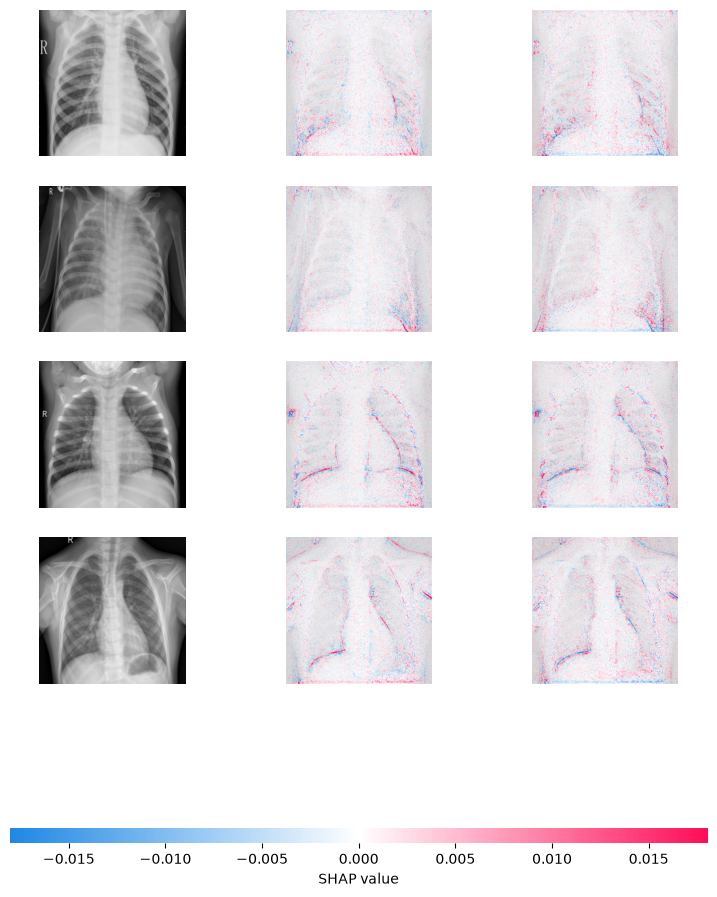

Saved SHAP visualization to: /home/mega-pc/pneumo-xai/explanations/shap_epoch1_20261015_215752.png


In [12]:
with torch.no_grad():
    predicted_classes = model(explain_images).argmax(dim=1).cpu().numpy()

for i in range(len(explain_indices)):
    true_label = CLASS_NAMES[explain_labels[i]]
    pred_label = CLASS_NAMES[predicted_classes[i]]
    print(f"Image {i}: true={true_label}, predicted={pred_label}")

# SHAP's image_plot expects channel-last arrays in [0, 1].
shap_numpy = [sv.transpose(0, 2, 3, 1) for sv in shap_values]
image_numpy = explain_images.detach().cpu().numpy().transpose(0, 2, 3, 1)

shap.image_plot(shap_numpy, image_numpy)

EXPLANATIONS_DIR.mkdir(parents=True, exist_ok=True)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
output_path = (
    EXPLANATIONS_DIR
    / f"shap_epoch{checkpoint['epoch']}_{timestamp}.png"
)
plt.savefig(output_path, bbox_inches="tight", dpi=150)
plt.close()

print(f"Saved SHAP visualization to: {output_path}")